In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)

## 2. Load the data

**Dataset:** [Credit Card Fraud Detection (Kaggle, ULB)](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) —
284,807 transactions made by European cardholders over two days in September 2013, of which 492 are frauds.

| Column | Meaning |
|---|---|
| `V1`–`V28` | Anonymised features (PCA components of the original confidential data) |
| `Time` | Seconds elapsed since the first transaction in the dataset |
| `Amount` | Transaction amount |
| `Class` | Target: 1 = fraud, 0 = normal |

The cell below downloads the file with `kagglehub`. If that fails, it asks you to upload `creditcard.csv`.

In [ ]:
DATA_FILE = "creditcard.csv"

if not os.path.exists(DATA_FILE):
    try:
        import kagglehub
        dataset_path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
        DATA_FILE = os.path.join(dataset_path, "creditcard.csv")
    except Exception as exc:
        print("Automatic download failed:", exc)
        print("Please upload creditcard.csv downloaded from Kaggle.")
        from google.colab import files
        files.upload()

df = pd.read_csv(DATA_FILE)
print("Shape:", df.shape)
df.head()

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 3. Exploratory data analysis

In [ ]:
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

class_counts = df["Class"].value_counts().sort_index()
print("\nClass counts:")
print(class_counts.rename({0: "Normal", 1: "Fraud"}))
fraud_rate = class_counts[1] / len(df)
print(f"\nFraud rate: {fraud_rate:.4%}")
print(f"A model that ALWAYS predicts 'normal' would score {1 - fraud_rate:.2%} accuracy "
      "while catching zero frauds -> accuracy is the wrong metric here.")

Missing values: 0
Duplicate rows: 1081

Class counts:
Class
Normal    284315
Fraud        492
Name: count, dtype: int64

Fraud rate: 0.1727%
A model that ALWAYS predicts 'normal' would score 99.83% accuracy while catching zero frauds -> accuracy is the wrong metric here.


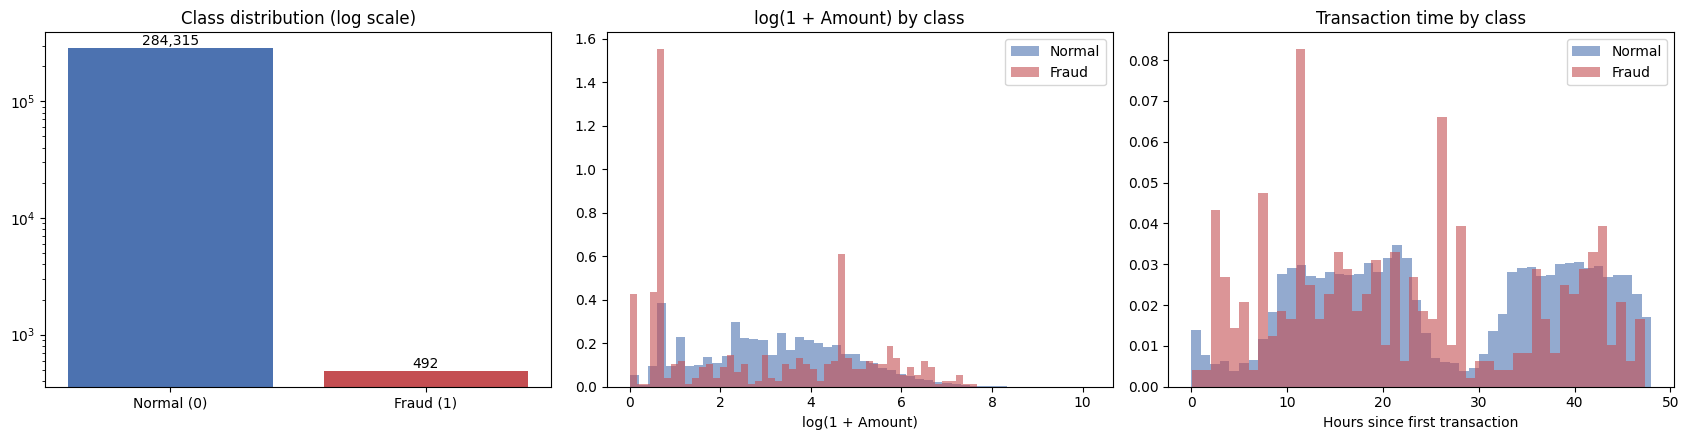

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].bar(["Normal (0)", "Fraud (1)"], class_counts.values, color=["#4C72B0", "#C44E52"])
axes[0].set_yscale("log")
axes[0].set_title("Class distribution (log scale)")
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom")

for label, color, name in [(0, "#4C72B0", "Normal"), (1, "#C44E52", "Fraud")]:
    subset = df[df["Class"] == label]
    axes[1].hist(np.log1p(subset["Amount"]), bins=50, density=True, alpha=0.6, color=color, label=name)
    axes[2].hist(subset["Time"] / 3600, bins=48, density=True, alpha=0.6, color=color, label=name)

axes[1].set_title("log(1 + Amount) by class")
axes[1].set_xlabel("log(1 + Amount)")
axes[1].legend()
axes[2].set_title("Transaction time by class")
axes[2].set_xlabel("Hours since first transaction")
axes[2].legend()

plt.tight_layout()
plt.savefig("figures/eda_overview.png", dpi=150, bbox_inches="tight")
plt.show()

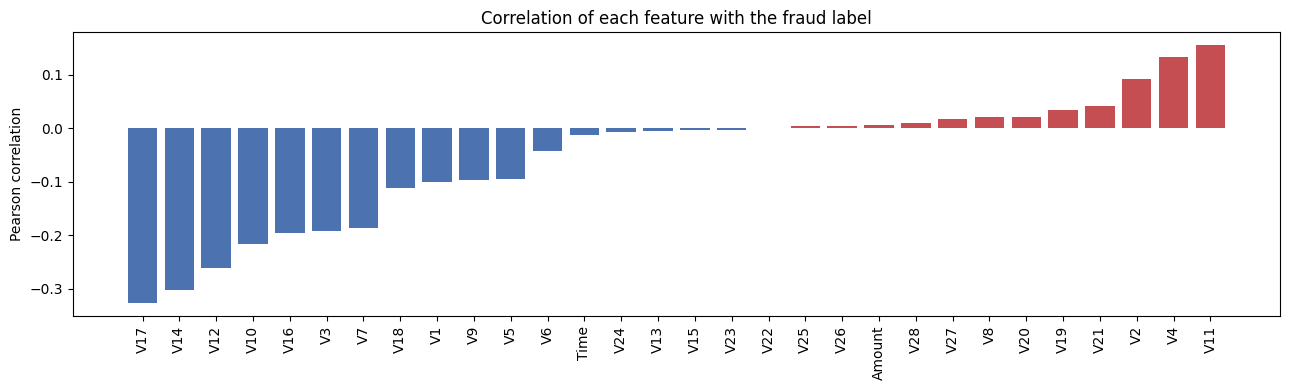

In [ ]:
correlations = df.drop(columns="Class").corrwith(df["Class"]).sort_values()

plt.figure(figsize=(13, 4))
plt.bar(correlations.index, correlations.values,
        color=np.where(correlations.values > 0, "#C44E52", "#4C72B0"))
plt.xticks(rotation=90)
plt.title("Correlation of each feature with the fraud label")
plt.ylabel("Pearson correlation")
plt.tight_layout()
plt.savefig("figures/feature_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

**EDA findings → preprocessing decisions**

- **Extreme class imbalance** (≈1 fraud per 580 transactions) → use **class weights**, a **stratified** split,
  and judge models by **PR-AUC, precision, recall and F1**, not accuracy.
- **`Amount` is highly skewed** → apply `log(1 + Amount)` before scaling.
- **`Time`** only counts seconds from the start of a 2-day window, so it would not generalise to new data → **dropped**.
- **Duplicate rows** exist → removed **before** splitting so the same transaction cannot appear in both train and test (data leakage).
- No missing values. Several PCA features (e.g. `V14`, `V17`, `V12`) are strongly related to fraud.

## 4. Preprocessing

Apply the decisions above: drop duplicates and `Time`, log-transform `Amount`, then split into **train / validation / test** (70% / 15% / 15%, stratified).

- Both models are **unsupervised**: they are trained on **normal transactions only**.
- The **validation set** (with its labels) is used only to choose the bottleneck size and the alert threshold.
- The **test set** is used only once, in the final comparison.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 42

data = df.drop_duplicates().drop(columns="Time")
data["Amount"] = np.log1p(data["Amount"])

X = data.drop(columns="Class").values
y = data["Class"].values

# 70% train / 15% validation / 15% test
X_rest, X_test, y_rest, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_rest, y_rest, test_size=0.15 / 0.85, stratify=y_rest, random_state=SEED)

scaler = StandardScaler().fit(X_train)
X_train, X_val, X_test = scaler.transform(X_train), scaler.transform(X_val), scaler.transform(X_test)

X_train_normal = X_train[y_train == 0]   # unsupervised: learn what "normal" looks like
X_val_normal = X_val[y_val == 0]
print("Train (normal only):", X_train_normal.shape)
print("Validation:", X_val.shape, "| frauds:", y_val.sum())
print("Test:", X_test.shape, "| frauds:", y_test.sum())

Train (normal only): (198277, 29)
Validation: (42559, 29) | frauds: 71
Test: (42559, 29) | frauds: 71


## 5. Model 1 — Autoencoder

The autoencoder learns to compress and rebuild normal transactions. Frauds look different, so they are rebuilt badly:
the **reconstruction error** is the anomaly score.

The most important hyperparameter is the **bottleneck size**: a smaller bottleneck forces stronger compression, so unusual
transactions are rebuilt worse. Three sizes are tried and compared by **PR-AUC on the validation set**.

,bottleneck,epochs,val_PR_AUC
0,2,20,0.2908
1,4,20,0.4551
2,6,20,0.5808


Best bottleneck: 6


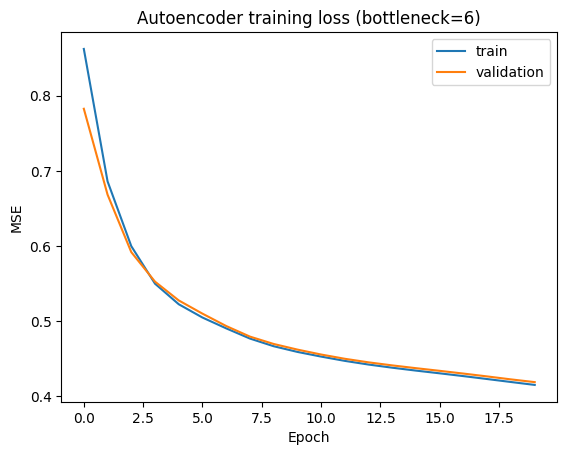

In [ ]:
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import average_precision_score

def build_autoencoder(bottleneck):
    model = keras.Sequential([
        keras.Input(shape=(X_train_normal.shape[1],)),
        keras.layers.Dense(20, activation="relu"),
        keras.layers.Dense(14, activation="relu"),
        keras.layers.Dense(bottleneck),
        keras.layers.Dense(14, activation="relu"),
        keras.layers.Dense(20, activation="relu"),
        keras.layers.Dense(X_train_normal.shape[1], activation="linear"),
    ])
    model.compile(optimizer="adam", loss="mse")
    return model

def reconstruction_error(model, X):
    return np.mean(np.square(X - model.predict(X, batch_size=8192, verbose=0)), axis=1)

search = []
trained = {}
for bottleneck in [2, 4, 6]:
    keras.utils.set_random_seed(SEED)
    model = build_autoencoder(bottleneck)
    early_stopping = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
    history = model.fit(X_train_normal, X_train_normal,
                        validation_data=(X_val_normal, X_val_normal),
                        epochs=20, batch_size=1024, callbacks=[early_stopping], verbose=0)
    pr_auc = average_precision_score(y_val, reconstruction_error(model, X_val))
    search.append({"bottleneck": bottleneck, "epochs": len(history.history["loss"]), "val_PR_AUC": round(pr_auc, 4)})
    trained[bottleneck] = (model, history)

search = pd.DataFrame(search)
display(search)

best_bottleneck = int(search.loc[search["val_PR_AUC"].idxmax(), "bottleneck"])
autoencoder, history = trained[best_bottleneck]
print("Best bottleneck:", best_bottleneck)

plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.title(f"Autoencoder training loss (bottleneck={best_bottleneck})")
plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.legend()
plt.show()

In [ ]:
ae_train_scores = reconstruction_error(autoencoder, X_train_normal)
ae_val_scores = reconstruction_error(autoencoder, X_val)
ae_test_scores = reconstruction_error(autoencoder, X_test)

## 6. Model 2 — Isolation Forest

Isolation Forest isolates points with random splits; anomalies are isolated in fewer splits.
`score_samples` returns higher = more normal, so we negate it to get an anomaly score (higher = more suspicious).

In [ ]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(n_estimators=200, random_state=42, n_jobs=-1)
iso.fit(X_train_normal)

if_train_scores = -iso.score_samples(X_train_normal)
if_val_scores = -iso.score_samples(X_val)
if_test_scores = -iso.score_samples(X_test)

## 7. Comparison

- **ROC-AUC / PR-AUC** compare the raw scores without choosing a threshold (PR-AUC matters most with this imbalance).
- Precision, recall and F1 depend on the **threshold**. Two ways of choosing it are compared:
  - **99.5th percentile:** flag the top 0.5% of normal training scores. This uses no labels at all.
  - **Tuned on validation:** pick the threshold that gives the best F1 on the validation set. This uses a small number of labeled
    frauds, but never the test set, so the test results stay honest.

In [ ]:
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             precision_score, recall_score, f1_score,
                             precision_recall_curve)

def best_f1_threshold(y_true, scores):

    p, r, t = precision_recall_curve(y_true, scores)
    f1 = 2 * p * r / (p + r + 1e-12)
    return t[np.argmax(f1[:-1])]

models = {
    "Autoencoder": (ae_train_scores, ae_val_scores, ae_test_scores),
    "Isolation Forest": (if_train_scores, if_val_scores, if_test_scores),
}

rows = []
for name, (train_s, val_s, test_s) in models.items():
    thresholds = {
        "99.5th percentile": np.percentile(train_s, 99.5),
        "Tuned on validation": best_f1_threshold(y_val, val_s),
    }
    for how, threshold in thresholds.items():
        y_pred = (test_s > threshold).astype(int)
        rows.append({
            "Model": name,
            "Threshold": how,
            "ROC-AUC": roc_auc_score(y_test, test_s),
            "PR-AUC": average_precision_score(y_test, test_s),
            "Precision": precision_score(y_test, y_pred),
            "Recall": recall_score(y_test, y_pred),
            "F1": f1_score(y_test, y_pred),
            "Alerts": int(y_pred.sum()),
            "Frauds caught": int(y_pred[y_test == 1].sum()),
        })

results = pd.DataFrame(rows).set_index(["Model", "Threshold"]).round(3)
print("Frauds in test set:", y_test.sum())
results

Frauds in test set: 71


ROC-AUC  PR-AUC  Precision  Recall  \
Model            Threshold                                                 
Autoencoder      99.5th percentile      0.914   0.477      0.194   0.775   
                 Tuned on validation    0.914   0.477      0.644   0.408   
Isolation Forest 99.5th percentile      0.942   0.109      0.110   0.408   
                 Tuned on validation    0.942   0.109      0.184   0.127   

                                         F1  Alerts  Frauds caught  
Model            Threshold                                          
Autoencoder      99.5th percentile    0.310     284             55  
                 Tuned on validation  0.500      45             29  
Isolation Forest 99.5th percentile    0.174     263             29  
                 Tuned on validation  0.150      49              9

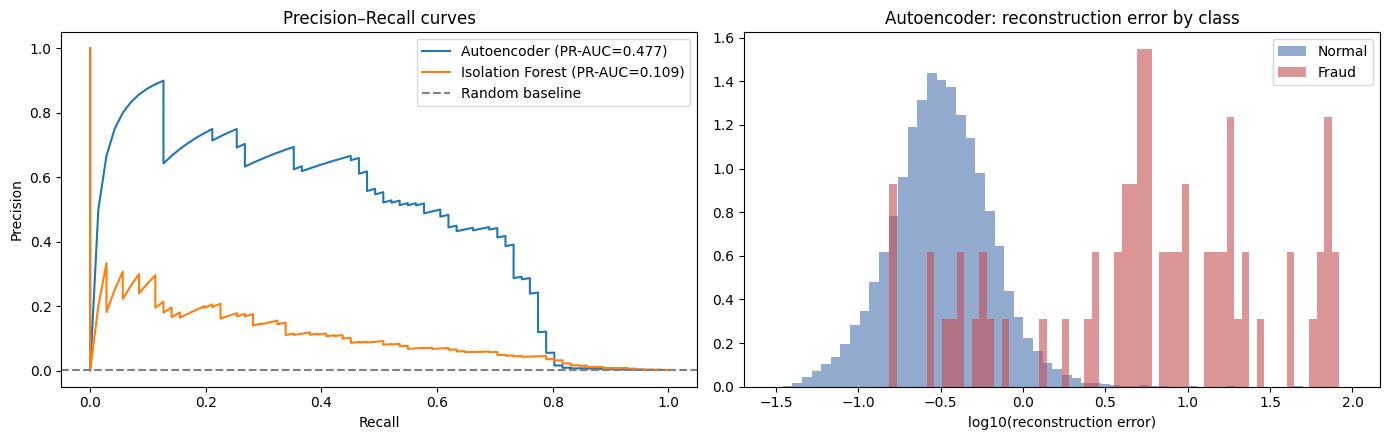

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

for name, (_, _, test_s) in models.items():
    p, r, _ = precision_recall_curve(y_test, test_s)
    axes[0].plot(r, p, label=f"{name} (PR-AUC={average_precision_score(y_test, test_s):.3f})")
axes[0].axhline(y_test.mean(), color="grey", ls="--", label="Random baseline")
axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precision")
axes[0].set_title("Precision–Recall curves"); axes[0].legend()

axes[1].hist(np.log10(ae_test_scores[y_test == 0]), bins=60, density=True, alpha=0.6, color="#4C72B0", label="Normal")
axes[1].hist(np.log10(ae_test_scores[y_test == 1]), bins=60, density=True, alpha=0.6, color="#C44E52", label="Fraud")
axes[1].set_xlabel("log10(reconstruction error)")
axes[1].set_title("Autoencoder: reconstruction error by class"); axes[1].legend()

plt.tight_layout()
plt.savefig("figures/unsupervised_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

**Takeaways**

- Both models never saw a fraud label during training, yet both rank frauds far above random (PR-AUC vs the random baseline).
- ROC-AUC is similar for both, but **PR-AUC** shows the autoencoder is much better at the top of the ranking, which is where alerts are raised.
- The **threshold** is the main lever for precision, recall and F1. Tuning it on a small labeled validation set moves the
  model to its best precision/recall balance instead of a fixed 0.5% alert rate.
- Precision and recall still trade off against each other: a higher threshold means fewer false alarms but more missed frauds.
- Unsupervised detectors flag "unusual", not "fraud", so in practice they work best as a first filter or alongside a supervised model.